# RealNVP — coupling layers, Two Moons, and likelihood in PyTorch

> **Notebook goal:** implement RealNVP from scratch, derive affine coupling, train the model on Two Moons, and analyze its samples and density. The code does not rely on a prebuilt flow library.

RealNVP (Real-valued Non-Volume Preserving) addresses a key challenge: how to obtain a nonlinear transformation whose inverse and log-determinant are cheap. Its answer is the **affine coupling layer**: part of the input stays unchanged and predicts the transformation parameters for the remaining dimensions.

**Contents:** Two Moons → coupling algebra → PyTorch implementation → NLL training → density and sample visualization → analysis and experiments.


## 1. The Two Moons dataset

Two Moons is a nonlinear, low-dimensional distribution with two connected, curved regions. It is easy to visualize: we can see where the model places probability mass and how the data map to the Gaussian base.

We generate the data synthetically, so no dataset download is needed. A train/validation split prevents us from evaluating the fit only on training examples.


PyTorch: 2.4.1+cpu | device: cpu


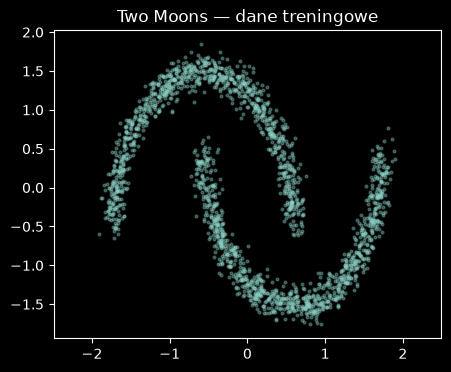

In [1]:
import math, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import make_moons

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)

X, _ = make_moons(n_samples=12000, noise=0.06, random_state=SEED)
X = torch.tensor(X, dtype=torch.float32)
# Standardization helps optimization; density is reported in these coordinates.
mean, std = X[:9000].mean(0), X[:9000].std(0)
X = (X - mean) / std
perm = torch.randperm(len(X)); train = X[perm[:9000]].to(device); valid = X[perm[9000:]].to(device)
plt.figure(figsize=(5, 4)); plt.scatter(train[:2000,0].cpu(), train[:2000,1].cpu(), s=4, alpha=.35); plt.axis('equal'); plt.title('Two Moons — dane treningowe'); plt.show()

## 2. Affine coupling: derivation

Split a vector $x=(x_a,x_b)$, where $x_a$ is the conditioning part. A network $s,t$ takes $x_a$ and returns vectors with the same length as $x_b$:
$$y_a=x_a,\qquad y_b=x_b\odot\exp(s(x_a))+t(x_a).$$

The inverse is immediate because $y_a=x_a$ provides the same parameters:
$$x_a=y_a,\qquad x_b=(y_b-t(y_a))\odot\exp(-s(y_a)).$$

The Jacobian has a block-triangular form:
$$J=\begin{bmatrix}I&0\\ *&\operatorname{diag}(\exp(s))\end{bmatrix},\quad \log|\det J|=\sum_j s_j(x_a).$$

This is the key trick: networks $s,t$ can be deep and nonlinear, but the log-determinant does not require autodiff for every matrix entry. We alternate masks or permutations so every dimension sometimes plays the role of $a$. In 2D, the mask alternately keeps x or y unchanged.

Scale is often limited with $s=c\tanh(\hat s)$, since an uncontrolled $\exp(s)$ can explode or vanish. The constant $c$ sets the maximum log-scale.


In [ ]:
class CouplingNet(nn.Module):
    """Small MLP predicting shift and raw log-scale."""
    def __init__(self, in_dim, out_dim, hidden=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.Tanh(),
                                  nn.Linear(hidden, hidden), nn.Tanh(),
                                  nn.Linear(hidden, 2*out_dim))
        # Start near identity for more stable optimization.
        nn.init.zeros_(self.net[-1].weight); nn.init.zeros_(self.net[-1].bias)
        self.out_dim = out_dim
    def forward(self, x):
        shift, raw_scale = self.net(x).chunk(2, dim=-1)
        log_scale = 1.5 * torch.tanh(raw_scale)
        return shift, log_scale

class AffineCoupling(nn.Module):
    def __init__(self, dim, mask):
        super().__init__()
        self.register_buffer('mask', torch.tensor(mask, dtype=torch.float32))
        self.net = CouplingNet(dim, dim)
    def forward(self, x):
        xa = x * self.mask
        shift, log_scale = self.net(xa)
        active = 1.0 - self.mask
        y = xa + active * (x * torch.exp(log_scale) + shift)
        logdet = (log_scale * active).sum(dim=-1)
        return y, logdet
    def inverse(self, y):
        ya = y * self.mask
        shift, log_scale = self.net(ya)
        active = 1.0 - self.mask
        x = ya + active * ((y - shift) * torch.exp(-log_scale))
        inverse_logdet = -(log_scale * active).sum(dim=-1)
        return x, inverse_logdet

layer = AffineCoupling(2, [1, 0]).to(device)
test_x = torch.randn(5, 2, device=device)
test_y, ld = layer(test_x); recovered, ild = layer.inverse(test_y)
print('Maximum inverse error:', (test_x-recovered).abs().max().item())
print('Forward + inverse log-determinant ~ 0:', (ld+ild).abs().max().item())

Maximum inverse error: 0.0
Forward + inverse log-determinant ~ 0: 0.0


## 3. The full flow and its density

For a composition of layers, pass data through the layers and sum their log-determinants. The base log density is the sum of the log densities of independent standard Gaussians. Sampling runs in the other direction: draw from the base, then apply the layer inverses in reverse order.

Order matters: if $z=f_K(\cdots f_1(x))$, inversion starts with $f_K^{-1}$. In this API, `forward` maps data to the base (convenient for likelihood); `inverse` maps the base back to data.


In [3]:
class RealNVP(nn.Module):
    def __init__(self, dim=2, n_layers=8):
        super().__init__()
        masks = [[1., 0.] if i % 2 == 0 else [0., 1.] for i in range(n_layers)]
        self.layers = nn.ModuleList([AffineCoupling(dim, m) for m in masks])
        self.dim = dim
    def to_base(self, x):
        logdet = torch.zeros(x.shape[0], device=x.device)
        z = x
        for layer in self.layers:
            z, ld = layer(z); logdet += ld
        return z, logdet
    def log_prob(self, x):
        z, logdet = self.to_base(x)
        log_pz = -0.5 * (z.square() + math.log(2*math.pi)).sum(-1)
        return log_pz + logdet  # forward to base: + log|det dz/dx|
    @torch.no_grad()
    def sample(self, n):
        z = torch.randn(n, self.dim, device=next(self.parameters()).device)
        for layer in reversed(self.layers): z, _ = layer.inverse(z)
        return z

flow = RealNVP(n_layers=8).to(device)
print('Test log probabilities:', flow.log_prob(test_x))


Test log probabilities: tensor([-2.4848, -1.9343, -2.3931, -2.0932, -2.7579], grad_fn=<AddBackward0>)


## 4. Maximum-likelihood training

We minimize $-\mathbb E_{x\sim p_{data}}[\log p_\theta(x)]$. Unlike a GAN, there is no discriminator or heuristic objective: density follows directly from the base and the Jacobian. We compute validation NLL on held-out examples.

Reduce the configuration if your environment is slow. Training should be brief for 2D data; randomized minibatches vary the order of observations.


epoch  10 | train NLL   2.007 | valid NLL   1.981
epoch  20 | train NLL   1.660 | valid NLL   1.700
epoch  30 | train NLL   1.637 | valid NLL   1.581
epoch  40 | train NLL   1.512 | valid NLL   1.506
epoch  50 | train NLL   1.464 | valid NLL   1.442
epoch  60 | train NLL   1.457 | valid NLL   1.449
epoch  70 | train NLL   1.411 | valid NLL   1.401
epoch  80 | train NLL   1.409 | valid NLL   1.422


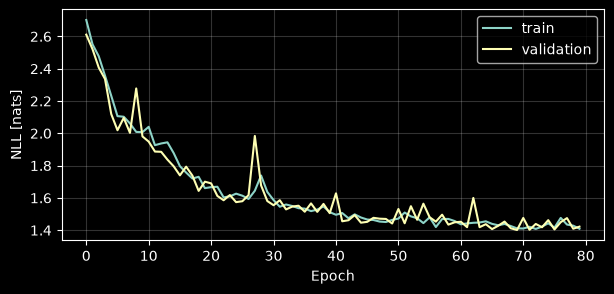

In [4]:
epochs, batch_size = 80, 512
optimizer = torch.optim.Adam(flow.parameters(), lr=1e-3, weight_decay=1e-6)
train_history, valid_history = [], []
for epoch in range(epochs):
    flow.train(); order = torch.randperm(len(train), device=device); losses=[]
    for idx in order.split(batch_size):
        loss = -flow.log_prob(train[idx]).mean()
        optimizer.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(flow.parameters(), 10.0)
        optimizer.step(); losses.append(loss.detach())
    flow.eval()
    with torch.no_grad(): val_nll = -flow.log_prob(valid).mean().item()
    train_nll = torch.stack(losses).mean().item()
    train_history.append(train_nll); valid_history.append(val_nll)
    if (epoch+1) % 10 == 0: print(f'epoch {epoch+1:3d} | train NLL {train_nll:7.3f} | valid NLL {val_nll:7.3f}')

plt.figure(figsize=(7,3)); plt.plot(train_history,label='train'); plt.plot(valid_history,label='validation'); plt.xlabel('Epoch'); plt.ylabel('NLL [nats]'); plt.legend(); plt.grid(alpha=.2); plt.show()

## 5. Samples and the density map

Likelihood and samples answer different questions. Density contours show where the model assigns mass; random samples show whether both moons are covered without gaps or artifacts. A smooth density plot does not guarantee a perfect model, but for this synthetic problem it provides a clear diagnostic.


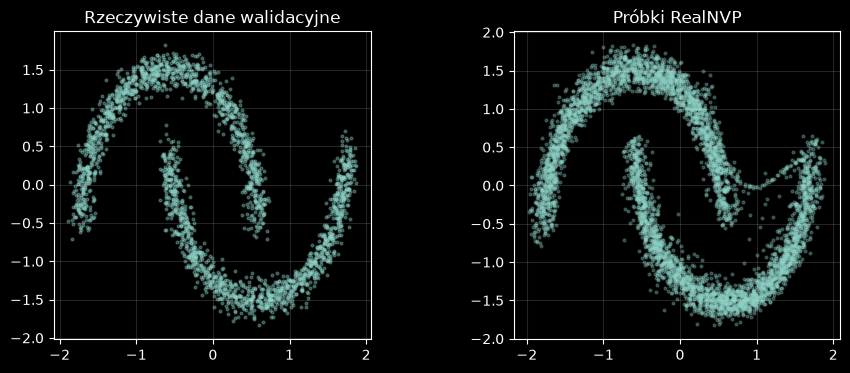

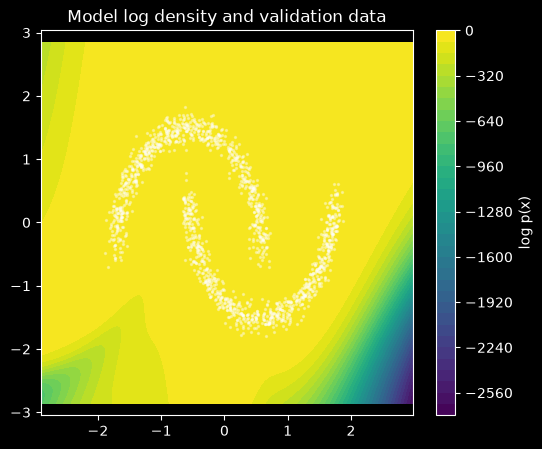

In [5]:
flow.eval()
with torch.no_grad():
    samples = flow.sample(5000).cpu()
    lo = train.min(0).values.cpu() - 1.0; hi = train.max(0).values.cpu() + 1.0
    gx, gy = torch.meshgrid(torch.linspace(lo[0],hi[0],180), torch.linspace(lo[1],hi[1],180), indexing='xy')
    points = torch.stack([gx.flatten(),gy.flatten()], dim=-1).to(device)
    logp = flow.log_prob(points).reshape(gx.shape).cpu()

fig, ax = plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(valid[:2500,0].cpu(), valid[:2500,1].cpu(),s=4,alpha=.35); ax[0].set_title('Rzeczywiste dane walidacyjne')
ax[1].scatter(samples[:,0],samples[:,1],s=4,alpha=.3); ax[1].set_title('Próbki RealNVP')
for a in ax: a.set_aspect('equal'); a.grid(alpha=.15)
plt.show()
plt.figure(figsize=(6,5)); plt.contourf(gx,gy,logp,levels=35,cmap='viridis'); plt.colorbar(label='log p(x)'); plt.scatter(valid[:1500,0].cpu(),valid[:1500,1].cpu(),s=2,c='white',alpha=.35); plt.title('Model log density and validation data'); plt.axis('equal'); plt.show()

## 6. Analysis, pitfalls, and experiments

**Common implementation mistakes**
- Wrong sign: when mapping data $x\to z$, add $\log|\det dz/dx|$ to the base log density.
- Forgetting to sum over dimensions in the base log density or over transformed dimensions in the log-determinant.
- Inverting layers in forward order instead of reverse order.
- Never changing masks, which leaves one dimension untransformed.
- Using an excessive scale: `exp(log_scale)` can overflow; limiting it with `tanh` helps.
- Tuning on the test set instead of the validation set.

**Interpreting NLL:** the value is in nats per example (2D). Compare only with the same representation and dimension. Standardizing data shifts log density by the constant Jacobian of that transformation; the plot and NLL here refer to standardized coordinates.

**Experiments:** vary the number of layers (2, 4, 8, 12), MLP width, log-scale limit, Two Moons noise, and learning rate. Track train/validation NLL and samples. Check invertibility on several batches after training.

**RealNVP limitations:** coupling layers leave part of the input unchanged at each step, so multiple layers and permutations are needed; affine coupling also restricts the local family of transformations. Image models need a multiscale architecture, squeeze operations, and much larger networks. This example focuses on the mechanics rather than image quality.

## Summary

Affine coupling provides an invertible nonlinear transformation with a simple inverse and a log-determinant equal to the sum of log-scales. Alternating layers ensure that every dimension is transformed. Maximum likelihood directly fits the flow density, and samples are easy to generate from the base.

## Key takeaways

- An affine coupling layer leaves one partition unchanged and transforms the other with scale and shift predicted from the unchanged partition.
- Its triangular Jacobian makes $\log|\det J|$ a simple sum of predicted log-scales.
- Alternating masks lets every dimension be transformed across the stack of layers.
- For data-to-base evaluation, add $\log|\det dz/dx|$ to the base log density; invert layers in reverse order when sampling.
- Two Moons visualizations complement validation NLL: inspect both density coverage and generated samples.
